<a href="https://colab.research.google.com/github/Elight-dotcom/data-mining/blob/main/DM_M9_3124600100_Ardanu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M9 - Clustering - Data Mining

Nama : Ardanu Egitya Ash Shafah  
NRP : 3124600100  
Kelas : D4 IT D

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

## 1. dataset

Membaca `transaction.csv` ke dalam DataFrame pandas dan menyimpannya di variabel `dataset`, lalu menampilkannya.

In [19]:
data_path = '/content/drive/MyDrive/PENS/Semester 5/Data Mining/transaction.csv'

dataset = pd.read_csv(data_path)

dataset

,InvoiceNo,StockCode,Qty,InvoiceDate,CustomerID,Country
0,537626,22725,830,12/7/2010 14:57,12347,Iceland
1,537626,22729,948,12/7/2010 14:57,12347,Iceland
2,537626,22195,695,12/7/2010 14:57,12347,Iceland
3,542237,22725,636,1/26/2011 14:30,12347,Iceland
4,542237,22729,536,1/26/2011 14:30,12347,Iceland
...,...,...,...,...,...,...
10541,543911,21700,455,2/14/2011 12:46,17829,United Arab Emirates
10542,543911,22111,578,2/14/2011 12:46,17829,United Arab Emirates
10543,543911,22112,163,2/14/2011 12:46,17829,United Arab Emirates
10544,564428,23296,545,8/25/2011 11:27,17844,Canada


In [20]:
print("Jumlah baris :", dataset.shape[0])
print("Jumlah kolom :", dataset.shape[1])
dataset.info()

Jumlah baris : 10546
Jumlah kolom : 6
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10546 entries, 0 to 10545
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   InvoiceNo    10546 non-null  int64 
 1   StockCode    10546 non-null  int64 
 2   Qty          10546 non-null  int64 
 3   InvoiceDate  10546 non-null  object
 4   CustomerID   10546 non-null  int64 
 5   Country      10546 non-null  object
dtypes: int64(4), object(2)
memory usage: 494.5+ KB


## 2. country

Menghitung berapa kali tiap negara muncul pada dataset (jumlah baris per negara), disimpan di `country`.

In [21]:
country = dataset["Country"].value_counts()
country

,count
Country,
Germany,2269
France,2109
EIRE,1620
Netherlands,634
Spain,539
Belgium,486
Switzerland,434
Portugal,367
Australia,356


## 3. transaksi

Menghitung banyaknya transaksi pada tiap negara. Satu kode `InvoiceNo` dihitung sebagai satu transaksi, sehingga yang dihitung adalah jumlah `InvoiceNo` **unik** per negara (bukan jumlah baris).  
Hasil disimpan di `transaksi`. Urutan negara mengikuti urutan abjad (hasil `groupby`).

In [22]:
transaksi = dataset.groupby("Country")["InvoiceNo"].nunique()
transaksi.name = "Transaksi"
transaksi

,Transaksi
Country,
Australia,44
Austria,12
Bahrain,1
Belgium,84
Brazil,1
Canada,3
Channel Islands,21
Cyprus,16
Czech Republic,2


## 4. cluster

Clustering terhadap jumlah transaksi per negara menggunakan **Average Linkage** dengan **k = 3**.  
Label cluster (0, 1, 2) disimpan di `cluster`; nomor labelnya hanya penanda dan belum menunjukkan tingkat transaksi.

In [23]:
X = transaksi.values.reshape(-1, 1)

model = AgglomerativeClustering(n_clusters=3, linkage="average")
cluster = model.fit_predict(X)

pd.DataFrame({"Country": transaksi.index, "Transaksi": transaksi.values, "Cluster": cluster})

,Country,Transaksi,Cluster
0,Australia,44,0
1,Austria,12,0
2,Bahrain,1,0
3,Belgium,84,0
4,Brazil,1,0
5,Canada,3,0
6,Channel Islands,21,0
7,Cyprus,16,0
8,Czech Republic,2,0
9,Denmark,18,0


## 5. centroid

`AgglomerativeClustering` tidak menyimpan centroid, jadi posisi centroid dihitung sebagai **rata-rata jumlah transaksi** dari anggota tiap cluster. Hasil disimpan di `centroid` (indeks = label cluster).

In [24]:
centroid = pd.Series(
    [X[cluster == k].mean() for k in range(3)],
    index=range(3),
    name="Centroid",
)
centroid.index.name = "Cluster"
centroid

,Centroid
Cluster,
0,18.787879
1,360.500000
2,224.000000


## 6. sorted
Mengurutkan posisi centroid secara **ascending**. Indeks pada hasil pengurutan tetap berisi label cluster asalnya, sehingga bisa dipakai untuk memetakan cluster ke kategori. Hasil disimpan di `sorted`.

> Catatan: nama `sorted` sesuai permintaan, tetapi nama ini menimpa fungsi bawaan Python `sorted()`. Notebook ini tidak memakai fungsi tersebut lagi setelah sel ini.

In [25]:
sorted = centroid.sort_values(ascending=True)
sorted

,Centroid
Cluster,
0,18.787879
2,224.000000
1,360.500000


## 7. Kategori transaksi rendah, sedang, dan tinggi

- Indeks **pertama** pada `sorted` → cluster transaksi **rendah**
- Indeks **terakhir** pada `sorted` → cluster transaksi **tinggi**
- Indeks **di antaranya** → cluster transaksi **sedang**

In [26]:
label_rendah = sorted.index[0]
label_sedang = list(sorted.index[1:-1])
label_tinggi = sorted.index[-1]

kategori = {label_rendah: "Rendah", label_tinggi: "Tinggi"}
for k in label_sedang:
    kategori[k] = "Sedang"

hasil = pd.DataFrame({
    "Country": transaksi.index,
    "Transaksi": transaksi.values,
    "Cluster": cluster,
})
hasil["Kategori"] = hasil["Cluster"].map(kategori)

print(f"Cluster rendah = {label_rendah}, sedang = {label_sedang}, tinggi = {label_tinggi}\n")
for nama in ["Rendah", "Sedang", "Tinggi"]:
    daftar = hasil[hasil["Kategori"] == nama]
    print(f"Transaksi {nama.upper()} ({len(daftar)} negara):")
    print(", ".join(daftar["Country"]))
    print()

Cluster rendah = 0, sedang = [2], tinggi = 1

Transaksi RENDAH (33 negara):
Australia, Austria, Bahrain, Belgium, Brazil, Canada, Channel Islands, Cyprus, Czech Republic, Denmark, European Community, Finland, Greece, Iceland, Israel, Italy, Japan, Lebanon, Lithuania, Malta, Netherlands, Norway, Poland, Portugal, RSA, Saudi Arabia, Singapore, Spain, Sweden, Switzerland, USA, United Arab Emirates, Unspecified

Transaksi SEDANG (1 negara):
EIRE

Transaksi TINGGI (2 negara):
France, Germany



In [27]:
hasil

,Country,Transaksi,Cluster,Kategori
0,Australia,44,0,Rendah
1,Austria,12,0,Rendah
2,Bahrain,1,0,Rendah
3,Belgium,84,0,Rendah
4,Brazil,1,0,Rendah
5,Canada,3,0,Rendah
6,Channel Islands,21,0,Rendah
7,Cyprus,16,0,Rendah
8,Czech Republic,2,0,Rendah
9,Denmark,18,0,Rendah


## 8. Visualisasi

Scatter plot dengan warna berbeda untuk tiap kategori hasil cluster. Sumbu x = urutan country, sumbu y = jumlah transaksi.

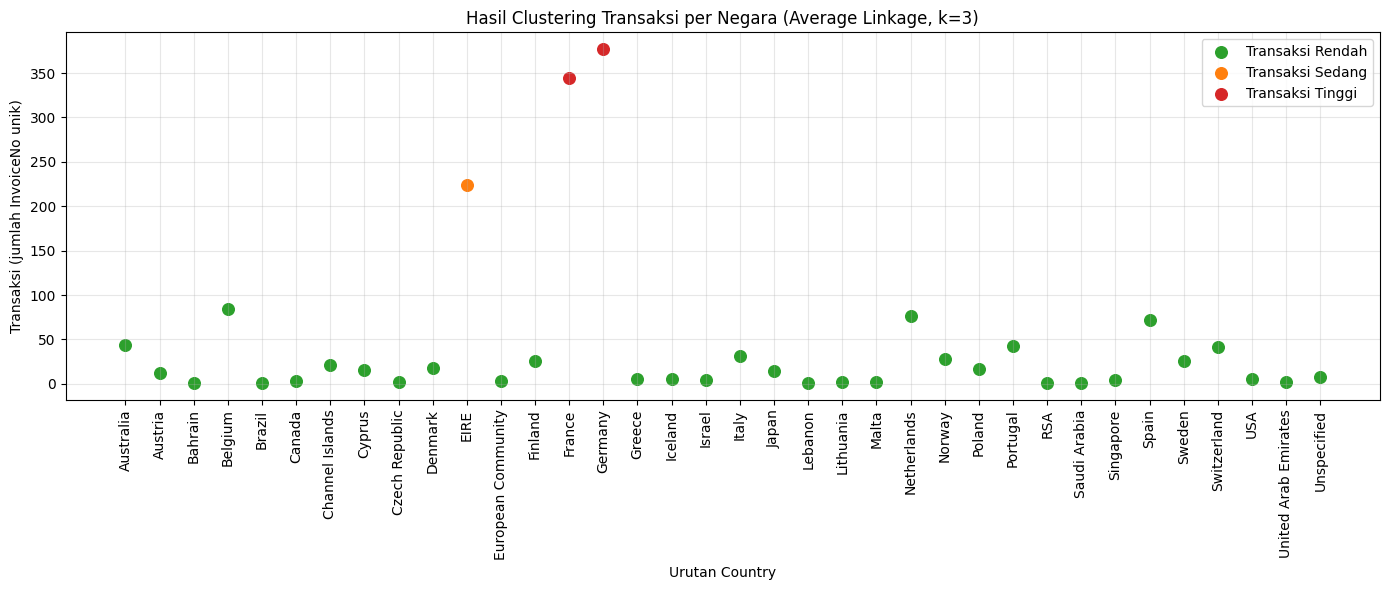

In [28]:
warna = {"Rendah": "tab:green", "Sedang": "tab:orange", "Tinggi": "tab:red"}
x = np.arange(len(hasil))

plt.figure(figsize=(14, 6))
for nama in ["Rendah", "Sedang", "Tinggi"]:
    m = (hasil["Kategori"] == nama).values
    plt.scatter(x[m], hasil["Transaksi"][m], c=warna[nama], s=70, label=f"Transaksi {nama}")

plt.xticks(x, hasil["Country"], rotation=90)
plt.xlabel("Urutan Country")
plt.ylabel("Transaksi (jumlah InvoiceNo unik)")
plt.title("Hasil Clustering Transaksi per Negara (Average Linkage, k=3)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()